# 2. Standard system

The original models — global OLS, ridge, LWLR, Monte Carlo linear, MCLLR and its two ablations — evaluated walk-forward (240-month training window, 12-month test window) on the same folds as every other model, against the historical-mean benchmark.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lrd import comparison as cmp

runs = {r.key: r for r in cmp.load_runs("app/data/default_run")[0]}  # rebuilt by scripts/build_app_results.py
bench = runs[cmp.BENCHMARK_KEY]
standard = [r for k, r in runs.items() if k.startswith("standard:")]
print(f"{len(bench.folds)} folds, {len(bench.dates)} test months: {bench.dates[0]:%b %Y} – {bench.dates[-1]:%b %Y}")

42 folds, 504 test months: Jul 1983 – Jun 2025


## 2.1 Results

OOS R² is relative to the historical mean. CW = Clark–West (one-sided, the appropriate test against the nested benchmark), DM = Diebold–Mariano. CER gain = extra certainty-equivalent return per year for a mean-variance investor (γ = 3).

In [2]:
cols = ["key", "rmse", "oos_r2_%", "cw_p", "dm_p", "coverage_95", "cer_gain_%", "sharpe"]
cmp.summarize(standard + [bench], bench)[cols].sort_values("oos_r2_%", ascending=False).round(4)

,key,rmse,oos_r2_%,cw_p,dm_p,coverage_95,cer_gain_%,sharpe
1,standard:ridge_linear,0.0448,0.0067,0.3635,0.9827,NaN,0.2130,0.4754
7,improved:historical_mean,0.0448,0.0000,0.5000,1.0000,0.9405,0.0000,0.4627
5,standard:mcllr_no_geometry,0.0454,-2.6209,0.4386,0.1349,0.3651,-0.3058,0.4423
3,standard:mc_linear,0.0455,-3.0855,0.5236,0.0913,0.3710,0.0000,0.4620
0,standard:global_linear,0.0455,-3.2824,0.6135,0.0600,NaN,-0.5636,0.4271
4,standard:mcllr,0.0462,-6.5768,0.7091,0.0108,0.3631,-0.6708,0.4253
2,standard:lwlr,0.0464,-7.3805,0.7735,0.0056,NaN,0.1417,0.4714
6,standard:mcllr_no_stochasticity,0.0494,-21.5080,0.8279,0.0002,NaN,0.2621,0.4813


## 2.2 Where the original MCLLR loses

Cumulative squared-error advantage over the benchmark: rising means beating it.

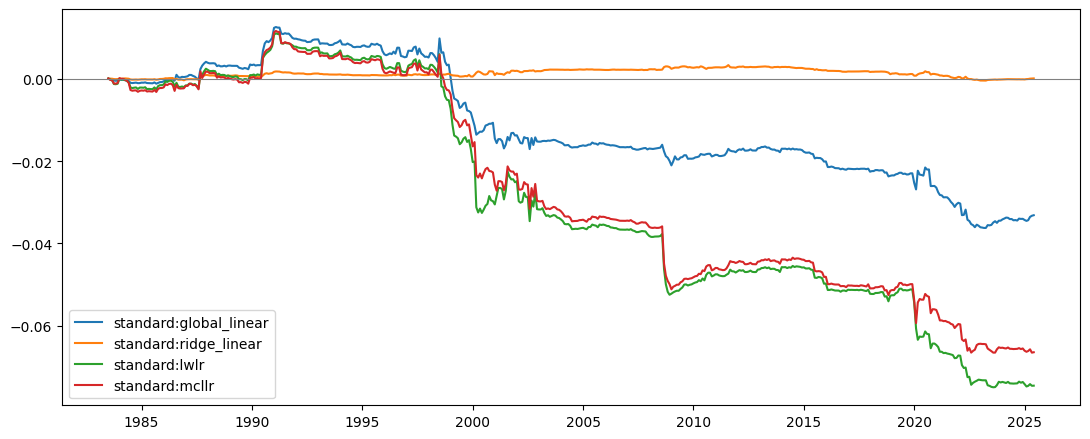

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for key in ["standard:global_linear", "standard:ridge_linear", "standard:lwlr", "standard:mcllr"]:
    adv = cmp.cumulative_advantage(runs[key], bench)
    ax.plot(adv.index, adv.values, label=key)
ax.axhline(0, color="gray", linewidth=0.8)
ax.legend()
plt.tight_layout()

## 2.3 Ablations and calibration

Removing geometry or stochasticity does not reveal a component that helps, and the Monte Carlo uncertainty is far too narrow (it ignores return noise).

In [4]:
levels = [0.5, 0.8, 0.9, 0.95]
pd.DataFrame({key: [cmp.coverage(runs[key], lv) for lv in levels]
              for key in ["standard:mc_linear", "standard:mcllr", "standard:mcllr_no_geometry"]},
             index=[f"nominal {lv:.0%}" for lv in levels]).round(3)

,standard:mc_linear,standard:mcllr,standard:mcllr_no_geometry
nominal 50%,0.145,0.147,0.151
nominal 80%,0.258,0.250,0.250
nominal 90%,0.317,0.306,0.319
nominal 95%,0.371,0.363,0.365
